## Deblurring Images with FB algorithm and PnP scheme

In [2]:
import deepinv as dinv 
import torch

device = dinv.utils.get_device()

Selected MPS device (Apple Silicon). Note that some PyTorch functions are not yet implemented for MPS. Please see https://github.com/deepinv/deepinv/issues/1177 and https://github.com/pytorch/pytorch/issues/141287 for details, and report an issue if you encounter problems. Otherwise, set the environment variable to fallback to CPU: import os; os.environ['PYTORCH_ENABLE_MPS_FALLBACK']='1'


Selected MPS device (Apple Silicon). Note that some PyTorch functions are not yet implemented for MPS. Please see https://github.com/deepinv/deepinv/issues/1177 and https://github.com/pytorch/pytorch/issues/141287 for details, and report an issue if you encounter problems. Otherwise, set the environment variable to fallback to CPU: import os; os.environ['PYTORCH_ENABLE_MPS_FALLBACK']='1'


/var/folders/lf/n9x1p6zj5g3gb2xzj13zzjhw0000gn/T/ipykernel_52241/2259561396.py:6: DeprecationWarning: Function 'gaussian_blur' is deprecated since 0.4.1. Use 'deepinv.physics.functional.blur.gaussian_blur' instead.
  dinv.physics.blur.gaussian_blur(sigma=(3, 3), angle = 0.3),


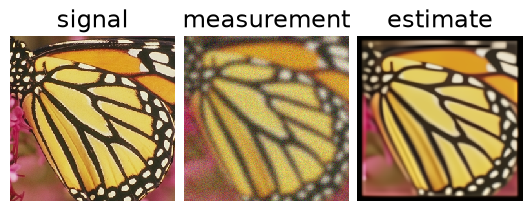

In [ ]:
device = dinv.utils.get_device()
x = dinv.utils.load_example("butterfly.png", img_size=256).to(device)

# Forward model: Gaussian blur + noise
physics = dinv.physics.Blur(
    dinv.physics.blur.gaussian_blur(sigma=(3, 3), angle =0.3),
    noise_model=dinv.physics.GaussianNoise(sigma=0.05),
    device=device,
)
y = physics(x)

# PnP = data fidelity + denoiser as implicit prior
denoiser = dinv.models.DRUNet(pretrained="download", device=device)
prior = dinv.optim.PnP(denoiser)
data_fidelity = dinv.optim.L2()

model = dinv.optim.optim_builder(
    iteration="PGD",            # or "HQS", "ADMM", ...
    prior=prior,
    data_fidelity=data_fidelity,
    max_iter=100,
    params_algo={"stepsize": 1.0, "g_param": 0.05},  # g_param = denoiser sigma
)

x_hat = model(y, physics)
dinv.utils.plot([x, y, x_hat], ["signal", "measurement", "estimate"])